# ZADANIE 1

a) Wykonaj poniższy skrypt i przeanalizuj go:

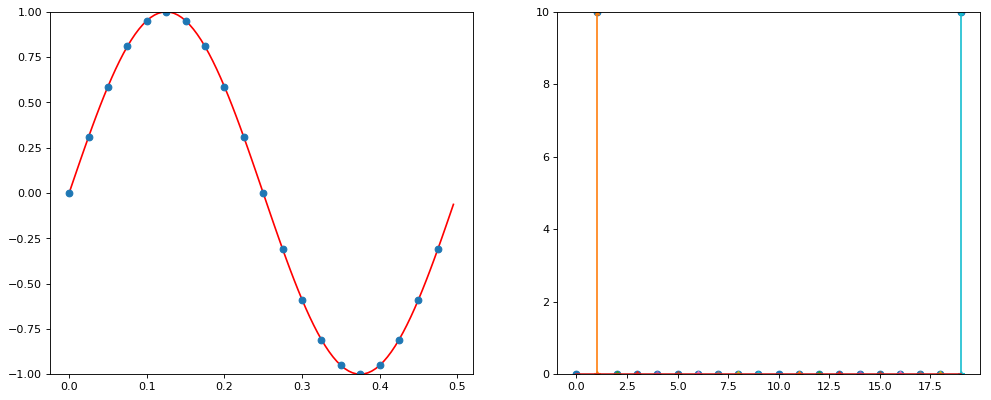

In [ ]:
from __future__ import division
from pylab import *
from numpy import *
from scipy import *
from ipywidgets import *
import math as mt

%matplotlib inline

A = 1
# Amplituda sygnału

LP = 1
# Liczba analizowanych pełnych przebiegów sygnału (okresów)
w = 40
# częstotliwość probkowania [Hz] sygnału
#(jak często w ciągu sekundy pobieramy informacje o wartości sygnału)

f = 2.0
# Czestotliwosc sygnalu [Hz]

T = 1.0/f
# Okres sygnalu [s] (jak długo trwa jeden przebieg sinusa)

TW = 1.0/w
# Okres probkowania [s] (co ile sekund pobieramy próbkę)

t = np.arange(0, LP*T, TW)
# generujemy momenty, w których pobieramy próbki

n = len(t)

FUNC = lambda t : A*sin(2*pi*t*f)
# def. funkcji (tutaj sinus)

signal = FUNC(t)
# funkcja sprobkowana

fig = plt.figure(figsize=(15, 6), dpi=80)
ax = fig.add_subplot(121)
## --- POMOCNICZY SYGNAL
base_t = np.arange(0, LP*T, 1.0/200.0)
base_signal = FUNC(base_t)
ax.plot(base_t, base_signal, linestyle='-', color='red')
ax.set_ylim([min(base_signal), max(base_signal)])
## ---
ax.plot(t, signal, 'o')

signal1 = fft(signal)
# sygnal w dziedzinie czestotliwosci
signal1 = abs(signal1)
# modul sygnalu

freqs = range(int(n))


ax = fig.add_subplot(122)
ymax = max(signal1)
if (ymax > 3.0):
    ax.set_ylim([0.0,ymax])
else:
    ax.set_ylim([0.0,3.0])
stem(freqs, signal1, '-*')

show()

UWAGA: do dalszych ćwiczeń warto powyższy skrypt przekształcić na funkcję o wielu argumentach, typu: amplituda, częstotliwość próbkowania, liczba przebiegów. Oczywiście dla wygody, należy nadać wartości domyślne argumentom funkcji.

In [ ]:
from __future__ import division
from pylab import *
from numpy import *
from scipy.fft import fft
from ipywidgets import *
import math as mt

%matplotlib inline


# Zdefiniuj funkcję
def sygnal(A=1, w=100, LP=1, f=1):
    T = 1.0/f
    TW = 1.0/w
    t = np.arange(0, LP*T, TW)
    n = len(t)

    FUNC = lambda t : A*sin(2*pi*t*f)
    signal = FUNC(t)
    fig = plt.figure(figsize=(15, 6), dpi=80)
    ax = fig.add_subplot(121)
    base_t = np.arange(0, LP*T, 1.0/200.0)
    base_signal = FUNC(base_t)
    ax.plot(base_t, base_signal, linestyle='-', color='red')
    ax.set_ylim([min(base_signal), max(base_signal)])
    ## ---
    ax.plot(t, signal, 'o')

    signal1 = fft(signal)
    signal1 = abs(signal1)

    freqs = range(int(n))


    ax = fig.add_subplot(122)
    ymax = max(signal1)
    if (ymax > 3.0):
        ax.set_ylim([0.0,ymax])
    else:
        ax.set_ylim([0.0,3.0])
    stem(freqs, signal1, '-*')

    show()


UWAGA DLA CHĘTNYCH: można wykorzystać 'interact', dzięki któremu można zmieniac parametry danej funkcji i na bieżąco obserwować zmiany. Poniższy kod przedstawia sposób wykorzystania interact:

In [ ]:
from ipykernel.pylab.backend_inline import flush_figures

def prosta(a=2, b=0):
    x = linspace(-5, 5, 100, endpoint=False) # punkty na osi OX [s]
    f = lambda x : a*x + b
    y = f(x)

    fig = plt.figure(figsize=(6, 3), dpi=80)
    ax = fig.add_subplot(111)
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.plot(x, y)
    flush_figures()

interact(prosta, a=(-5,5,0.5), b=(-5,5,0.5))


b) Zmień częstotliwość próbkowania na 50Hz.

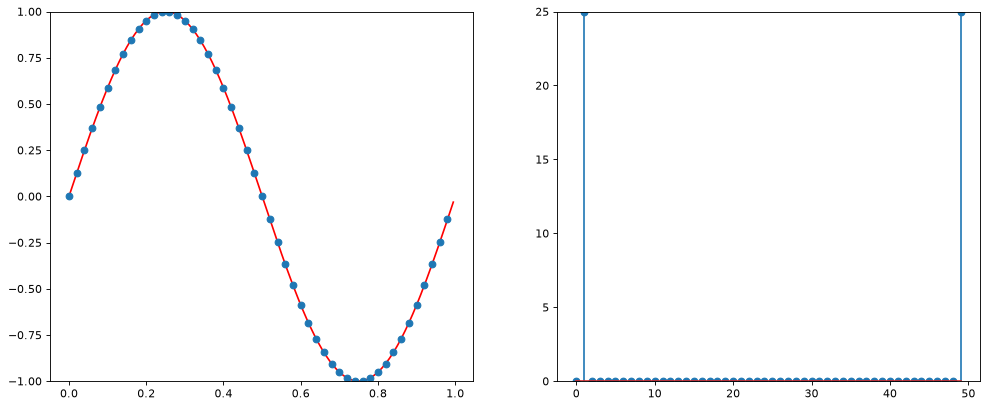

In [4]:
# w=50
sygnal(A = 1, w=50, LP=1, f=1)

c) Punkty na osi OX spektrum są teraz kolejnymi liczbami naturalnymi, a nie częstotliwościami w Hz. Popraw skrypt (funkcje), tak aby oś OX spektrum była w Hz (podpowiedź: oś OX rozpoczyna się od 0Hz, a kończy się na (prawie!)  Hz, gdzie  jest częstotliwością próbkowania). Następnie: Upewnij się, że spektrum dla 1Hz-owego sinusa i pięciu (LP=5) analizowanych przebiegów wygląda teraz prawidłowo.

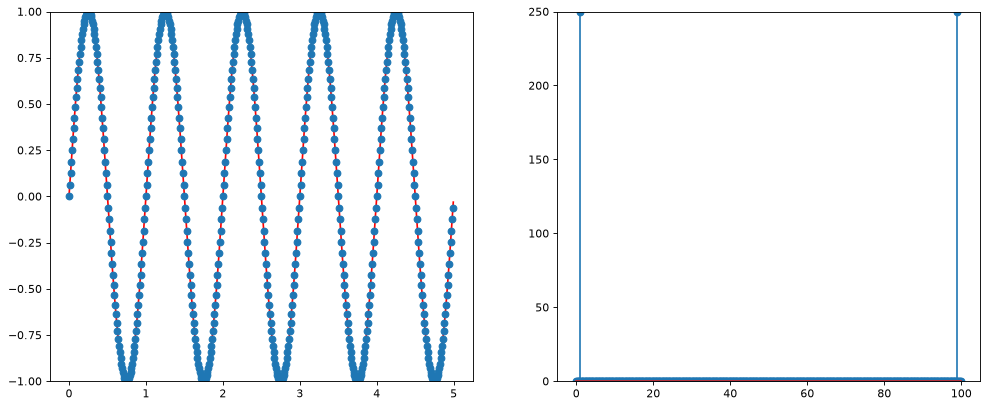

In [7]:
# popraw oś OX
from __future__ import division
from pylab import *
from numpy import *
from scipy.fft import fft
from ipywidgets import *
import math as mt

%matplotlib inline


# Zdefiniuj funkcję
def sygnal(A=1, w=100, LP=1, f=1):
    T = 1.0/f
    TW = 1.0/w
    t = np.arange(0, LP*T, TW)
    n = len(t)

    FUNC = lambda t : A*sin(2*pi*t*f)
    signal = FUNC(t)
    fig = plt.figure(figsize=(15, 6), dpi=80)
    ax = fig.add_subplot(121)
    base_t = np.arange(0, LP*T, 1.0/200.0)
    base_signal = FUNC(base_t)
    ax.plot(base_t, base_signal, linestyle='-', color='red')
    ax.set_ylim([min(base_signal), max(base_signal)])
    ## ---
    ax.plot(t, signal, 'o')

    signal1 = fft(signal)
    signal1 = abs(signal1)

    freqs = np.arange(int(n)) * (w / n)


    ax = fig.add_subplot(122)
    ymax = max(signal1)
    if (ymax > 3.0):
        ax.set_ylim([0.0,ymax])
    else:
        ax.set_ylim([0.0,3.0])
    stem(freqs, signal1, '-*')

    show()

sygnal(A = 1, w = 100, LP = 5, f = 1)


d) Podpisz osie obu wykresów, używając funkcji xlabel() i ylabel(). Pamiętaj o jednostkach.

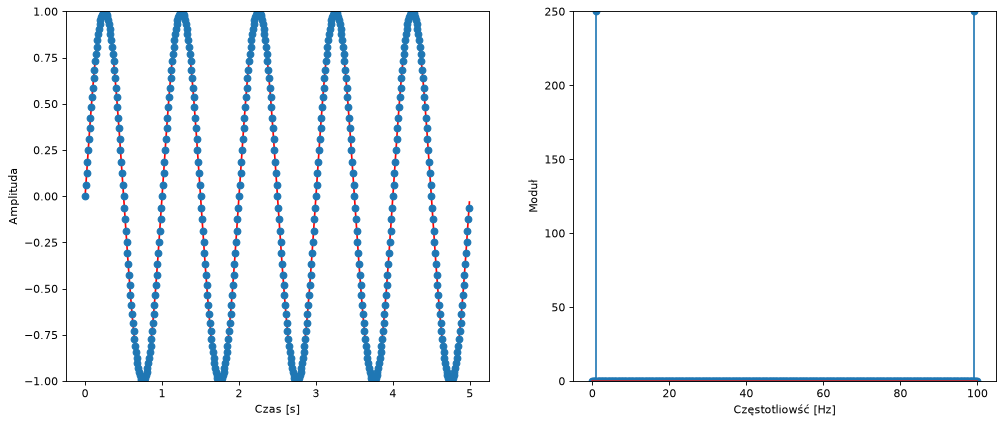

In [17]:
# Podpisz osie wykresów
from __future__ import division
from pylab import *
from numpy import *
from scipy.fft import fft
from ipywidgets import *
import math as mt

%matplotlib inline


# Zdefiniuj funkcję
def sygnal(A=1, w=100, LP=1, f=1):
    T = 1.0/f
    TW = 1.0/w
    t = np.arange(0, LP*T, TW)
    n = len(t)

    FUNC = lambda t : A*sin(2*pi*t*f)
    signal = FUNC(t)
    fig = plt.figure(figsize=(15, 6), dpi=80)
    ax1 = fig.add_subplot(121)
    base_t = np.arange(0, LP*T, 1.0/200.0)
    base_signal = FUNC(base_t)
    ax1.plot(base_t, base_signal, linestyle='-', color='red')
    ax1.set_xlabel('Czas [s]')
    ax1.set_ylabel('Amplituda')
    ax1.set_ylim([min(base_signal), max(base_signal)])
    ## ---
    ax1.plot(t, signal, 'o')

    signal1 = fft(signal)
    signal1 = abs(signal1)

    freqs = np.arange(int(n)) * (w / n)


    ax2 = fig.add_subplot(122)
    ymax = max(signal1)
    if (ymax > 3.0):
        ax2.set_ylim([0.0,ymax])
    else:
        ax2.set_ylim([0.0,3.0])
    stem(freqs, signal1, '-*')
    ax2.set_xlabel('Częstotliowść [Hz]')
    ax2.set_ylabel('Moduł')

    show()

sygnal(A = 1, w = 100, LP = 5, f = 1)


f) Porównaj spektrum funkcji $sin(2*pi*f*t)$, $2*sin(2*pi*f*t)$ i $3*sin(2*pi*f*t)$. Jak zmienia się wartość na osi OY na wykresie spektrum?

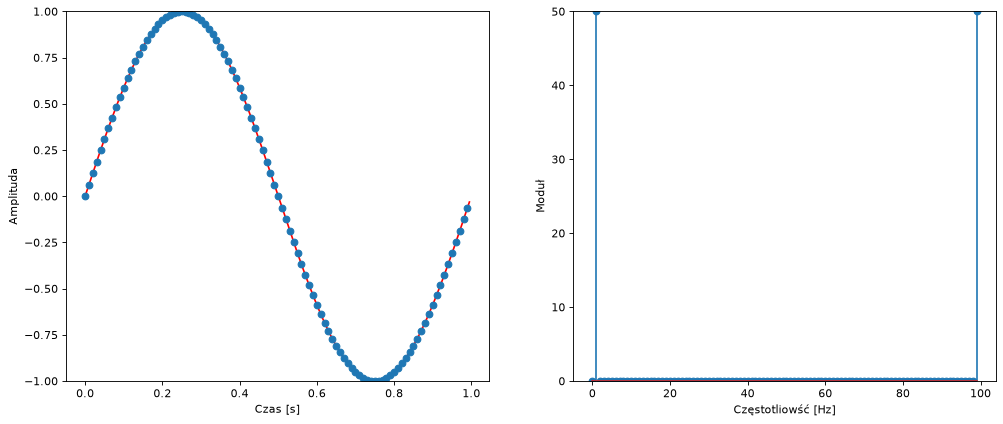

In [18]:
# f=1, A=1, LP=1
sygnal(A = 1, w = 100, LP = 1, f = 1)

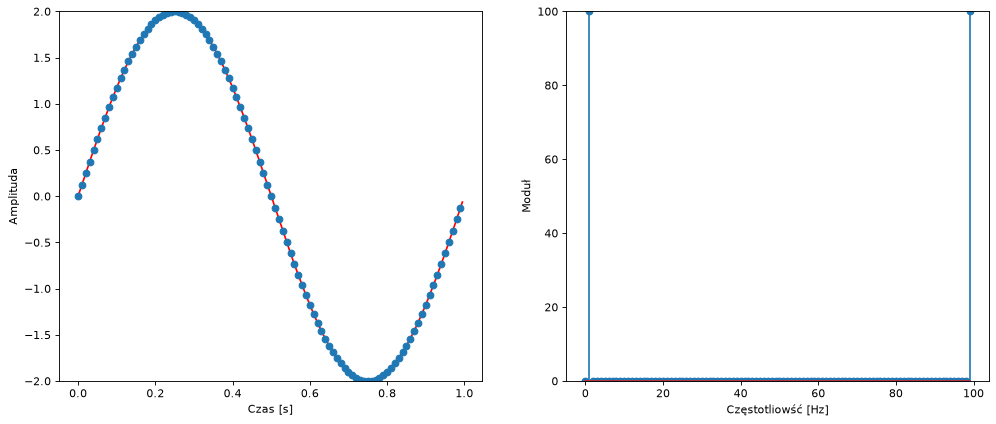

In [19]:
# f=1, A=2, LP=1
sygnal(A = 2, w = 100, LP = 1, f = 1)

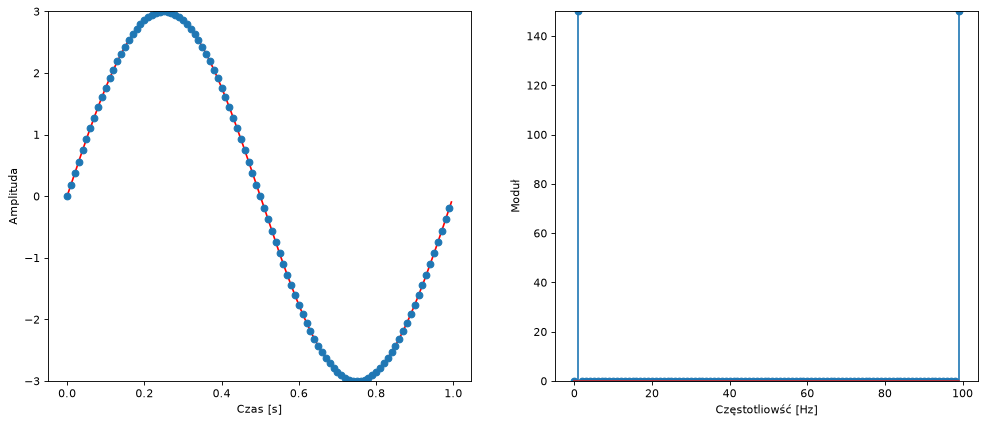

In [20]:
# f=1, A=3, LP=1
sygnal(A = 3, w = 100, LP = 1, f = 1)

g) Ile punktów jest na wykresach przy częstotliwości próbkowania 50Hz, T=1s? Zwiększ dwukrotnie liczbę próbek poprzez zwiększenie częstotliwości próbkowania. Następnie: dla $sin(2*pi*f*t)$ porównaj wartość na osi OY spektrum uzyskane w tym oraz poprzednim punkcie.

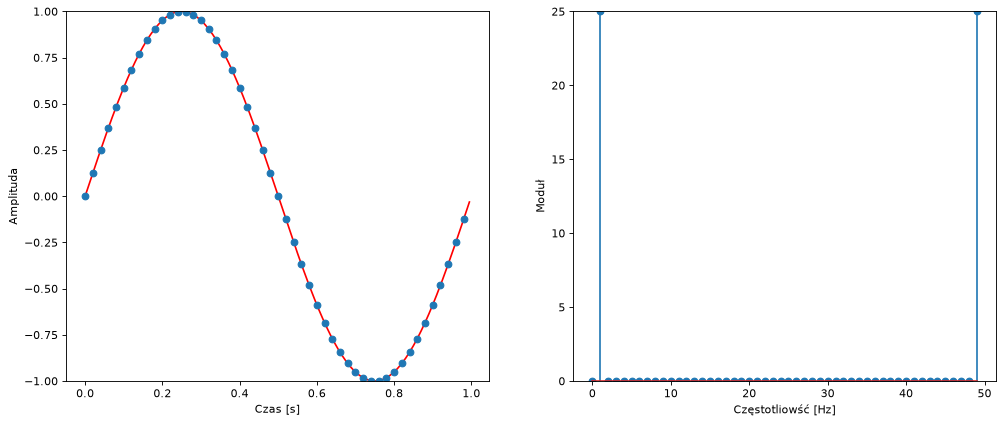

In [21]:
# f=1, w=50, LP=1
sygnal(A = 1, w = 50, LP = 1, f = 1)

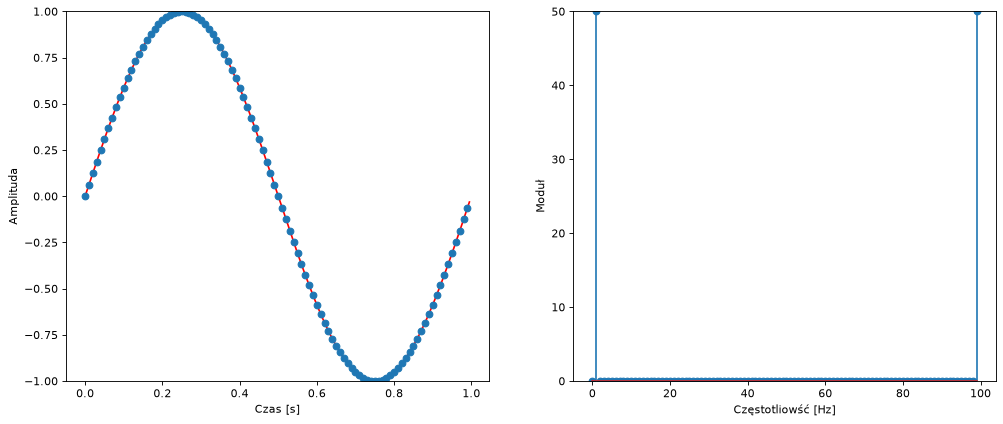

In [22]:
# f=1, w=100, LP=1
sygnal(A = 1, w =100, LP = 1, f = 1)

h) Na podstawie wyników uzyskanych w dwóch poprzednich punktach przeskaluj oś OY spektrum tak, aby wskazywała wartości amplitud badanych sygnałów. Sprawdź wyniki dla kilku wybranych funkcji.

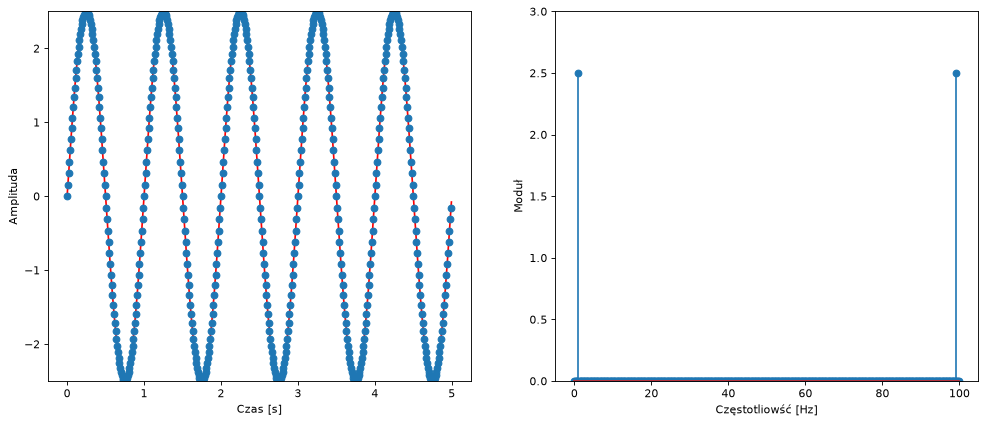

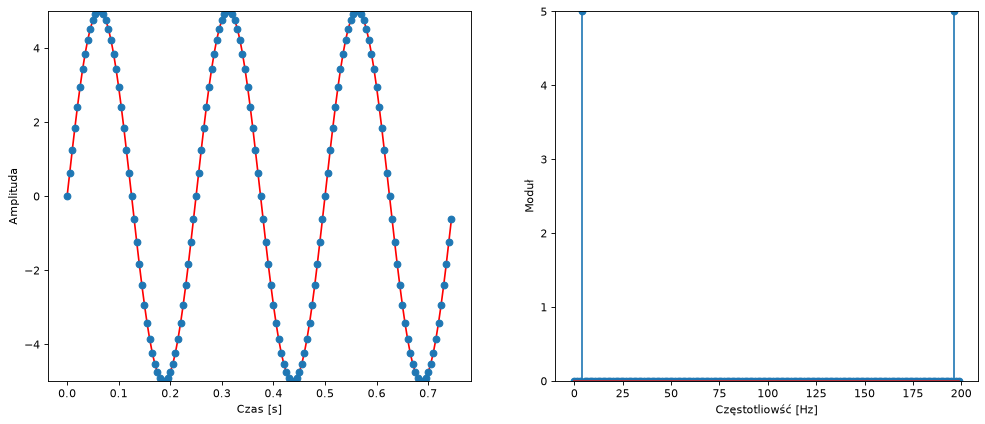

In [26]:
# popraw oś OY
from __future__ import division
from pylab import *
from numpy import *
from scipy.fft import fft
from ipywidgets import *
import math as mt

%matplotlib inline


# Zdefiniuj funkcję
def sygnal(A=1, w=100, LP=1, f=1):
    T = 1.0/f
    TW = 1.0/w
    t = np.arange(0, LP*T, TW)
    n = len(t)

    FUNC = lambda t : A*sin(2*pi*t*f)
    signal = FUNC(t)
    fig = plt.figure(figsize=(15, 6), dpi=80)
    ax1 = fig.add_subplot(121)
    base_t = np.arange(0, LP*T, 1.0/200.0)
    base_signal = FUNC(base_t)
    ax1.plot(base_t, base_signal, linestyle='-', color='red')
    ax1.set_xlabel('Czas [s]')
    ax1.set_ylabel('Amplituda')
    ax1.set_ylim([min(base_signal), max(base_signal)])
    ## ---
    ax1.plot(t, signal, 'o')

    signal1 = fft(signal)
    signal1 = abs(signal1) / (n / 2)

    freqs = np.arange(int(n)) * (w / n)


    ax2 = fig.add_subplot(122)
    ymax = max(signal1)
    if (ymax > 3.0):
        ax2.set_ylim([0.0,ymax])
    else:
        ax2.set_ylim([0.0,3.0])
    stem(freqs, signal1, '-*')
    ax2.set_xlabel('Częstotliowść [Hz]')
    ax2.set_ylabel('Moduł')

    show()

sygnal(A=2.5, w=100, LP=5, f=1)
sygnal(A=5, w=200, LP=3, f=4)


# Zadanie 2

Plik spots.txt zawiera wartości aktywności Słońca w kolejnych miesiącach. Wykreśl ten sygnał oraz jego spektrum. Za pomocą FFT, oblicz częstotliwość cyklu aktywności słonecznej.

# Zadanie 3

Wykreśl sygnał $sin(2*pi*t) + sin(4*pi*t)$, T=1s, w=20Hz. Za pomocą FFT, przekształć sygnał do dziedziny częstotliwości. Następnie usuń składowe o częstotliwości 2Hz. Tak zmodyfikowany sygnał przekształć do dziedziny czasu i wykreśl go.

Text(0, 0.5, 'Amplituda')

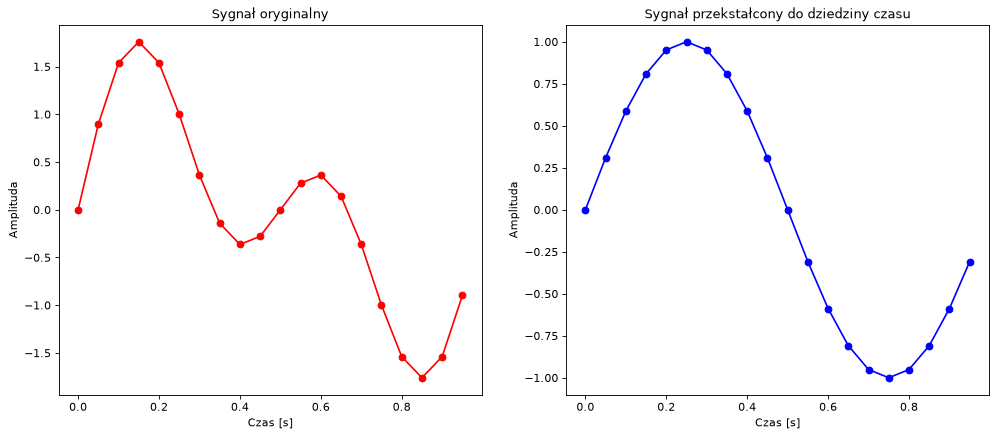

In [32]:
from __future__ import division
from pylab import *
from numpy import *
from scipy.fft import fft, ifft
from ipywidgets import *
import math as mt

%matplotlib inline

T = 1
w = 20
TW = 1/w
t = np.arange(0, T, TW)
n = len(t)

FUNC = lambda t : sin(2*pi*t) + sin(4*pi*t)
signal = FUNC(t)
signal1 = fft(signal)
freqs = np.arange(int(n)) * (w / n)

for signals in range(n):
    if freqs[signals] == 2 or freqs[signals] == w - 2:
        signal1[signals] = 0

signal2 = ifft(signal1).real

fig = plt.figure(figsize=(15, 6), dpi=80)
ax1 = fig.add_subplot(121)
ax1.plot(t, signal, '-o', color='red')
ax1.set_title('Sygnał oryginalny')
ax1.set_xlabel('Czas [s]')
ax1.set_ylabel('Amplituda')

ax2 = fig.add_subplot(122)
ax2.plot(t, signal2, '-o', color='blue')
ax2.set_title('Sygnał przekstałcony do dziedziny czasu')
ax2.set_xlabel('Czas [s]')
ax2.set_ylabel('Amplituda')



# Zadanie 4

Wczytaj plik err.wav. Wykreśl jego spektrum. Spróbuj także skali logarytmicznej. Określ dominujące w sygnale częstotliwości.